# Eigenvalues & Eigenvectors — Intuition in 2D

**Note:** This analysis is in 2-dimensional spaces (x and y; an orthonormal basis).

$$
\color{#5588ff}{\mathbf{e}_1 = \hat{x} = \begin{bmatrix} 1 \\ 0 \end{bmatrix}},
\qquad
\color{#d20000}{\mathbf{e}_2 = \hat{y} = \begin{bmatrix} 0 \\ 1 \end{bmatrix}}
$$

A general 2×2 matrix:

$$
\mathbf{A} = \begin{bmatrix}
A_{11} & A_{12} \\
A_{21} & A_{22}
\end{bmatrix}
$$

### The defining property

An **eigenvector** $\vec{\mathbf{v}} \neq \mathbf{0}$ of $\mathbf{A}$ satisfies

$$
\mathbf{A}\vec{\mathbf{v}} = \lambda \vec{\mathbf{v}}
$$

for some scalar $\lambda$ called the **eigenvalue** belonging to that eigenvector.

**Geometric meaning:** applying $\mathbf{A}$ to $\vec{\mathbf{v}}$ only *scales* it (stretches or squashes, and possibly flips it if $\lambda < 0$). The direction is unchanged. Every other direction gets both scaled *and* rotated.

For any square $n \times n$ matrix there are (counting multiplicity, over $\mathbb{C}$) exactly $n$ eigenvalues.

### Trace and determinant (2×2)

$$
\operatorname{tr}(\mathbf{A}) = A_{11} + A_{22}, \qquad
\det(\mathbf{A}) = A_{11}A_{22} - A_{12}A_{21}
$$

### Characteristic equation

Eigenvalues are the roots of

$$
\det(\mathbf{A} - \lambda \mathbf{I}) = 0.
$$

For a 2×2 matrix this expands to the quadratic

$$
\lambda^2 - \operatorname{tr}(\mathbf{A})\,\lambda + \det(\mathbf{A}) = 0.
$$

The solutions are

$$
\lambda_{1,2} = \frac{\operatorname{tr}(\mathbf{A}) \pm \sqrt{\operatorname{tr}(\mathbf{A})^2 - 4\det(\mathbf{A})}}{2}.
$$


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Circle, Ellipse
import matplotlib.patches as mpatches

plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True


## Example matrix

We pick a simple symmetric matrix so the eigenvalues are real and the eigenvectors are orthogonal (nice for plotting).

$$
\mathbf{A} = \begin{bmatrix} 2 & 1 \\ 1 & 2 \end{bmatrix}
$$

(You can change the entries later to experiment.)


In [15]:
A = np.array([[2., 5.],
              [3., 2.]])

# Eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(A)

# Force real values (safe for the symmetric matrix we're using)
eigenvalues = np.real_if_close(eigenvalues).astype(float)
eigenvectors = np.real_if_close(eigenvectors).astype(float)

print("Matrix A:")
print(A)
print("\nEigenvalues:", eigenvalues)
print("\nEigenvectors (columns):")
print(eigenvectors)

# Sort by eigenvalue magnitude for nicer display
idx = np.argsort(np.abs(eigenvalues))[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("\nSorted eigenvalues:", eigenvalues)
print("Corresponding unit eigenvectors:")
print(eigenvectors)


Matrix A:
[[2. 5.]
 [3. 2.]]

Eigenvalues: [ 5.87298335 -1.87298335]

Eigenvectors (columns):
[[ 0.79056942 -0.79056942]
 [ 0.61237244  0.61237244]]

Sorted eigenvalues: [ 5.87298335 -1.87298335]
Corresponding unit eigenvectors:
[[ 0.79056942 -0.79056942]
 [ 0.61237244  0.61237244]]


## Visualizing the action of $\mathbf{A}$ on many vectors

We take a collection of unit vectors uniformly spaced in angle.  
Each is drawn in blue (original).  
Its image under $\mathbf{A}$ is drawn in orange (transformed).

The two eigenvectors (and the directions they define) are highlighted in red/green.  
Notice that only those special directions stay collinear with their images — they are purely scaled.


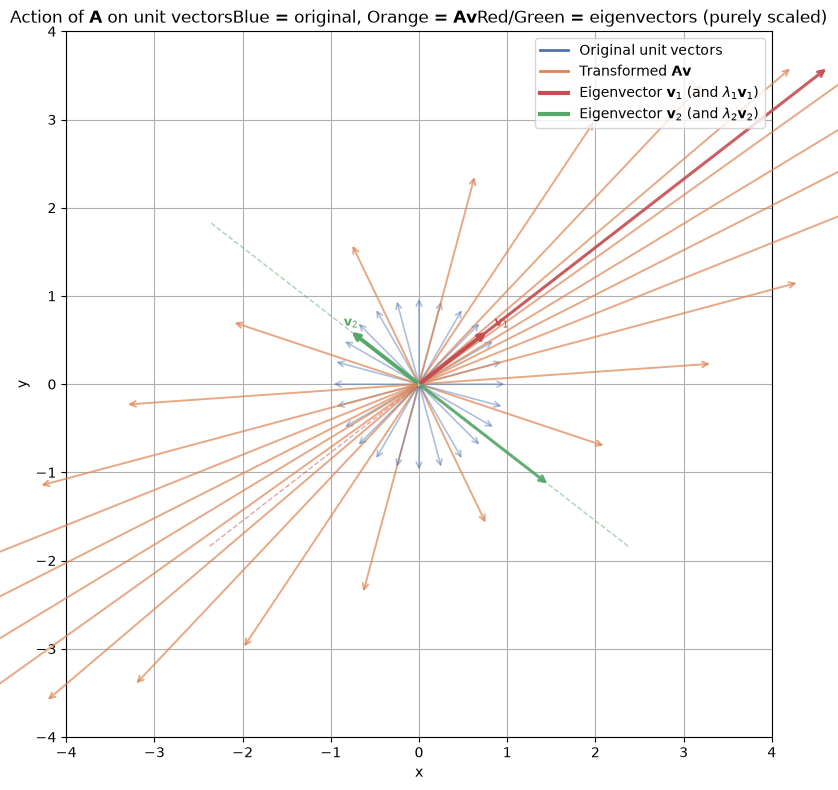

Eigenvalues (scaling factors along the eigen-directions): [ 5.87298335 -1.87298335]


In [ ]:
def plot_vector(ax, v, color='blue', label=None, lw=1.5, alpha=0.7, scale=1.0):
    """Draw an arrow from origin to v."""
    v = np.asarray(v) * scale
    ax.annotate('', xy=v, xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=color, lw=lw, alpha=alpha),
                annotation_clip=False)
    if label:
        ax.text(v[0]*1.08, v[1]*1.08, label, color=color, fontsize=9)

fig, ax = plt.subplots(figsize=(8, 8))

# Generate many unit vectors
n_vecs = 24
angles = np.linspace(0, 2*np.pi, n_vecs, endpoint=False)
unit_vecs = np.stack([np.cos(angles), np.sin(angles)], axis=1)

# Transform them
transformed = (A @ unit_vecs.T).T

# Plot original (blue) and transformed (orange)
for v, tv in zip(unit_vecs, transformed):
    plot_vector(ax, v, color='#4C72B0', alpha=0.45, lw=1.2)
    plot_vector(ax, tv, color='#DD8452', alpha=0.7, lw=1.4)

# Highlight the two eigenvectors and their images
colors_eig = ['#C44E52', '#55A868']
labels = [r'$\mathbf{v}_1$', r'$\mathbf{v}_2$']
for i, (lam, vec) in enumerate(zip(eigenvalues, eigenvectors.T)):
    # unit eigenvector
    plot_vector(ax, vec, color=colors_eig[i], label=labels[i], lw=2.8, alpha=1.0)
    # its image (should equal λ * vec)
    plot_vector(ax, lam * vec, color=colors_eig[i], lw=2.2, alpha=0.9,
                scale=1.0)  # already scaled by lam

# Draw the lines of the eigenvector directions (extend both ways)
for vec, c in zip(eigenvectors.T, colors_eig):
    t = np.linspace(-3, 3, 2)
    line = np.outer(t, vec)
    ax.plot(line[:, 0], line[:, 1], color=c, ls='--', alpha=0.5, lw=1)

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect('equal')
ax.set_title(r'Action of $\mathbf{A}$ on unit vectors'
             r'Blue = original, Orange = $\mathbf{A}\mathbf{v}$'
             r'Red/Green = eigenvectors (purely scaled)')
ax.set_xlabel('x')
ax.set_ylabel('y')

# Legend proxy
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#4C72B0', lw=2, label='Original unit vectors'),
    Line2D([0], [0], color='#DD8452', lw=2, label=r'Transformed $\mathbf{A}\mathbf{v}$'),
    Line2D([0], [0], color='#C44E52', lw=3, label=r'Eigenvector $\mathbf{v}_1$ (and $\lambda_1\mathbf{v}_1$)'),
    Line2D([0], [0], color='#55A868', lw=3, label=r'Eigenvector $\mathbf{v}_2$ (and $\lambda_2\mathbf{v}_2$)'),
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

print("Eigenvalues (scaling factors along the eigen-directions):", eigenvalues)


## Unit circle → ellipse

A linear transformation turns the unit circle into an ellipse.  
The semi-axes of that ellipse lie along the eigenvectors, and their lengths are the absolute values of the eigenvalues.

(This is especially clean when $\mathbf{A}$ is symmetric / positive-definite.)


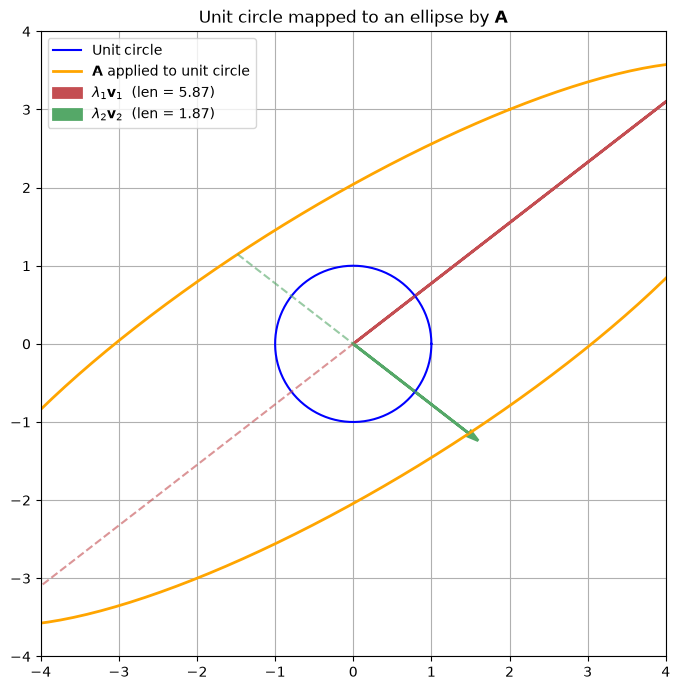

In [19]:
theta = np.linspace(0, 2*np.pi, 300)
circle = np.stack([np.cos(theta), np.sin(theta)])          # 2 × N
ellipse = A @ circle                                        # transformed

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(circle[0], circle[1], 'b-', lw=1.5, label='Unit circle')
ax.plot(ellipse[0], ellipse[1], 'orange', lw=2, label=r'$\mathbf{A}$ applied to unit circle')

# Eigenvectors scaled by |λ| (the semi-axes)
for i, (lam, vec) in enumerate(zip(eigenvalues, eigenvectors.T)):
    direction = vec * np.sign(lam) if lam != 0 else vec
    length = abs(lam)
    dx = float(direction[0] * length)
    dy = float(direction[1] * length)
    ax.arrow(0, 0, dx, dy,
             head_width=0.08, head_length=0.15,
             fc=colors_eig[i], ec=colors_eig[i], lw=2,
             label=rf'$\lambda_{i+1} \mathbf{{v}}_{i+1}$  (len = {length:.2f})')
    # full axis (both directions)
    ax.plot([-dx, dx], [-dy, dy], color=colors_eig[i], ls='--', alpha=0.6)

ax.set_aspect('equal')
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_title(r'Unit circle mapped to an ellipse by $\mathbf{A}$')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

## Direct comparison: eigenvector vs ordinary vector

Pick one eigenvector and one generic vector.  
Show $\mathbf{v}$ and $\mathbf{A}\mathbf{v}$ side-by-side (or overlaid).


/tmp/ipykernel_4930/181484329.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
/tmp/ipykernel_4930/181484329.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


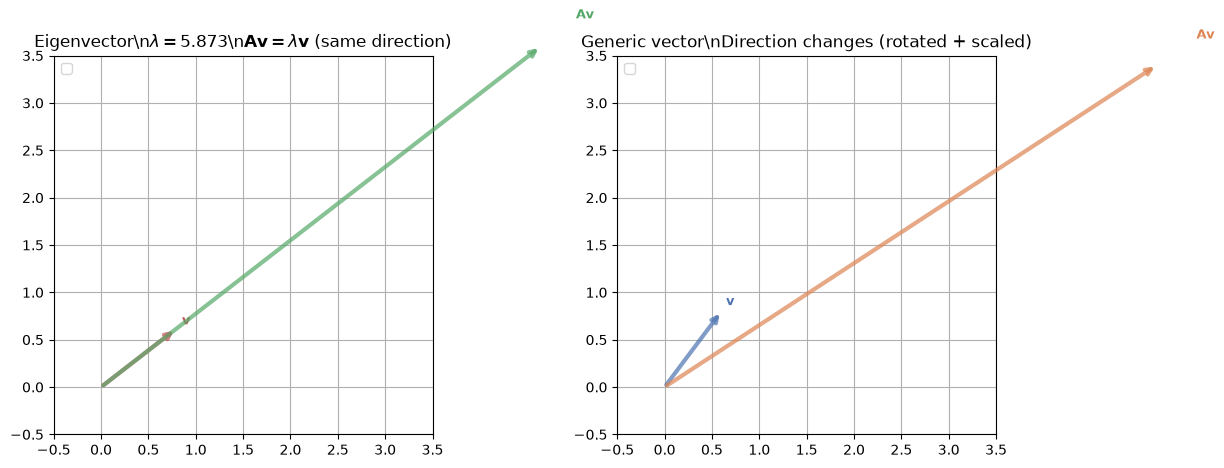

For the eigenvector: A v = [4.64300101 3.59645312],  λ v = [4.64300101 3.59645312]
Difference: 9.93e-16  (should be ~0)


In [18]:
# Eigenvector (first one)
v_eig = eigenvectors[:, 0]
lam = eigenvalues[0]
Av_eig = A @ v_eig

# A generic vector (not an eigenvector)
v_gen = np.array([0.6, 0.8])
v_gen = v_gen / np.linalg.norm(v_gen)   # make unit for fair comparison
Av_gen = A @ v_gen

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: eigenvector
ax = axes[0]
plot_vector(ax, v_eig, color='#C44E52', label=r'$\mathbf{v}$', lw=3)
plot_vector(ax, Av_eig, color='#55A868', label=r'$\mathbf{A}\mathbf{v}$', lw=3)
ax.set_title(rf'Eigenvector\n$\lambda = {lam:.3f}$\n$\mathbf{{A}}\mathbf{{v}} = \lambda\mathbf{{v}}$ (same direction)')
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(-0.5, 3.5)
ax.set_aspect('equal')
ax.legend()

# Right: generic
ax = axes[1]
plot_vector(ax, v_gen, color='#4C72B0', label=r'$\mathbf{v}$', lw=3)
plot_vector(ax, Av_gen, color='#DD8452', label=r'$\mathbf{A}\mathbf{v}$', lw=3)
ax.set_title(r'Generic vector\nDirection changes (rotated + scaled)')
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(-0.5, 3.5)
ax.set_aspect('equal')
ax.legend()

plt.tight_layout()
plt.show()

print(f"For the eigenvector: A v = {Av_eig},  λ v = {lam * v_eig}")
print(f"Difference: {np.linalg.norm(Av_eig - lam * v_eig):.2e}  (should be ~0)")


## Summary of the intuition

- Most vectors are both **rotated and scaled** by $\mathbf{A}$.
- A special set of directions (the **eigenvectors**) experience **only scaling**.
- The amount of that scaling is the corresponding **eigenvalue** $\lambda$.
- If $\lambda > 1$ the vector is stretched; $0 < \lambda < 1$ it is squashed; $\lambda < 0$ it is flipped and scaled; $\lambda = 0$ it is collapsed to the origin.
- In 2D these directions become the principal axes of the ellipse that the unit circle is mapped to.

### Things to try
1. Change the entries of `A` (try a non-symmetric matrix, a shear, a rotation, etc.).
2. Increase `n_vecs` for a denser fan of arrows.
3. Plot a grid of points instead of unit vectors and watch the parallelograms distort.
4. Add a negative eigenvalue and observe the flip.

---

*Notebook ready to run in your `.venv` kernel.*
